# Detecção de objetos com YOLO

Aula 3 - lib **ultralytics**.

1. Carregar um YOLO pré-treinado
2. Olhar o modelo por dentro
3. Inferência em imagem local
4. Formato do dataset e das labels
5. Treinar no coco8
6. Salvar, formatos e carregar

# 0. Instalando

`ultralytics` puxa o YOLO. `onnx` + `onnxscript` + `onnxruntime` entram no export/load ONNX.

In [29]:
%pip install -q ultralytics torch pillow matplotlib onnx onnxscript onnxruntime

Note: you may need to restart the kernel to use updated packages.


## 1. Imports

In [30]:
from pathlib import Path

import torch
from PIL import Image
from matplotlib import pyplot as plt
from matplotlib.patches import Rectangle
from ultralytics import YOLO

HERE = Path.cwd()
if not (HERE / "imagens" / "bus.jpg").exists():
    HERE = Path("exemplos-aula-03/detection")

PESOS_PT = HERE / "pesos" / "pt"
PESOS_ONNX = HERE / "pesos" / "onnx"
IMAGENS = HERE / "imagens"
DATA_YAML = HERE / "coco8" / "coco8.yaml"
PESOS_PT.mkdir(parents=True, exist_ok=True)
PESOS_ONNX.mkdir(parents=True, exist_ok=True)

device = 0 if torch.cuda.is_available() else "cpu"
print("Device:", device)
print("Pasta:", HERE)

Device: 0
Pasta: /home/thyago/luxai/deep-learning-pratica/exemplos-aula-03/detection


## 2. Carregar o modelo

`yolo11n.pt` = YOLO11 nano, pré-treinado no COCO (80 classes).
A primeira execução baixa os pesos.

In [31]:
pt_path = PESOS_PT / "yolo11n.pt"
model = YOLO(str(pt_path) if pt_path.exists() else "yolo11n.pt")
model

YOLO(
  (model): DetectionModel(
    (model): Sequential(
      (0): Conv(
        (conv): Conv2d(3, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
        (bn): BatchNorm2d(16, eps=0.001, momentum=0.03, affine=True, track_running_stats=True)
        (act): SiLU(inplace=True)
      )
      (1): Conv(
        (conv): Conv2d(16, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
        (bn): BatchNorm2d(32, eps=0.001, momentum=0.03, affine=True, track_running_stats=True)
        (act): SiLU(inplace=True)
      )
      (2): C3k2(
        (cv1): Conv(
          (conv): Conv2d(32, 32, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn): BatchNorm2d(32, eps=0.001, momentum=0.03, affine=True, track_running_stats=True)
          (act): SiLU(inplace=True)
        )
        (cv2): Conv(
          (conv): Conv2d(48, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn): BatchNorm2d(64, eps=0.001, momentum=0.03, affine=True, track_running_

## 3. Task e classes

In [32]:
print("Task:", model.task)
print("Número de classes:", len(model.names))
print(model.names[0], model.names[2], model.names[5])

Task: detect
Número de classes: 80
person car bus


## 4. Resumo do modelo

`info()` imprime o resumo e **devolve uma tupla**:
`(camadas, parâmetros, gradientes, GFLOPs)`.

Gradientes = 0 porque o modelo está em eval (ainda não há treino).

In [33]:
n_layers, n_params, n_grads, flops = model.info()
print("camadas:   ", n_layers)
print("parâmetros:", n_params)
print("gradientes:", n_grads)
print("GFLOPs:    ", round(flops, 2))

YOLO11n summary: 181 layers, 2,624,080 parameters, 0 gradients, 6.6 GFLOPs
camadas:    181
parâmetros: 2624080
gradientes: 0
GFLOPs:     6.61


## 5. Arquitetura

`model.model` é um `nn.Module` PyTorch. Abaixo, o nome de cada bloco.

In [34]:
for i, layer in enumerate(model.model.model):
    print(f"{i:02d}  {layer.__class__.__name__}")

00  Conv
01  Conv
02  C3k2
03  Conv
04  C3k2
05  Conv
06  C3k2
07  Conv
08  C3k2
09  SPPF
10  C2PSA
11  Upsample
12  Concat
13  C3k2
14  Upsample
15  Concat
16  C3k2
17  Conv
18  Concat
19  C3k2
20  Conv
21  Concat
22  C3k2
23  Detect


A primeira camada, por exemplo:

In [35]:
print(model.model.model[0])

Conv(
  (conv): Conv2d(3, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
  (bn): BatchNorm2d(16, eps=0.001, momentum=0.03, affine=True, track_running_stats=True)
  (act): SiLU(inplace=True)
)


## 6. Imagem local

W=810  H=1080  C=3  mode=RGB


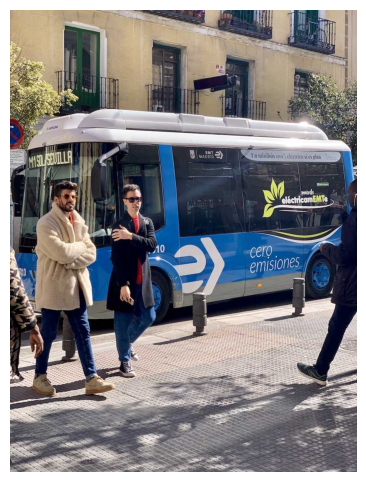

In [36]:
image_path = IMAGENS / "bus.jpg"
image = Image.open(image_path)
w, h = image.size
c = len(image.getbands())
print(f"W={w}  H={h}  C={c}  mode={image.mode}")

plt.figure(figsize=(8, 6))
plt.imshow(image)
plt.axis("off")
plt.show()

## 7. Inferência

`predict` devolve uma lista de `Results` (um por imagem).

In [37]:
results = model.predict(
    source=str(image_path),
    imgsz=(640, 640),
    conf=0.25,
    iou=0.7,
    max_det=300,
    half=False,
    device=device,
    save=False,
    save_txt=False,
    show=False,
    stream=False,
    verbose=False,
)
result = results[0]

print("tipo:      ", type(result).__name__)
print("imagem:    ", result.path)
print("orig_shape:", result.orig_shape, "(H, W)")
print("detecções: ", len(result.boxes))
print("speed ms:  ", {k: round(v, 2) for k, v in result.speed.items()})

tipo:       Results
imagem:     /home/thyago/luxai/deep-learning-pratica/exemplos-aula-03/detection/imagens/bus.jpg
orig_shape: (1080, 810) (H, W)
detecções:  5
speed ms:   {'preprocess': 1.43, 'inference': 3.24, 'postprocess': 0.6}


## 8. Tensores das detecções

`boxes.xyxy` = canto superior esquerdo e inferior direito.
`boxes.conf` = confiança. `boxes.cls` = id da classe.

In [38]:
boxes = result.boxes
print("Detecções:", len(boxes))
print("xyxy:\n", boxes.xyxy)
print("conf:", boxes.conf)
print("cls: ", boxes.cls)

Detecções: 5
xyxy:
 tensor([[3.8394e+00, 2.2935e+02, 7.9622e+02, 7.2841e+02],
        [6.7102e+02, 3.9483e+02, 8.0981e+02, 8.7871e+02],
        [4.7416e+01, 3.9957e+02, 2.3930e+02, 9.0420e+02],
        [2.2307e+02, 4.0869e+02, 3.4447e+02, 8.6043e+02],
        [2.1494e-02, 5.5608e+02, 6.8871e+01, 8.7237e+02]], device='cuda:0')
conf: tensor([0.9403, 0.8881, 0.8782, 0.8558, 0.6218], device='cuda:0')
cls:  tensor([5., 0., 0., 0., 0.], device='cuda:0')


## 9. Nome da classe + box

In [39]:
for box in boxes:
    cls_id = int(box.cls.item())
    conf = float(box.conf.item())
    xyxy = [round(v, 1) for v in box.xyxy[0].tolist()]
    print(f"{model.names[cls_id]:12s}  conf={conf:.2f}  xyxy={xyxy}")

bus           conf=0.94  xyxy=[3.8, 229.4, 796.2, 728.4]
person        conf=0.89  xyxy=[671.0, 394.8, 809.8, 878.7]
person        conf=0.88  xyxy=[47.4, 399.6, 239.3, 904.2]
person        conf=0.86  xyxy=[223.1, 408.7, 344.5, 860.4]
person        conf=0.62  xyxy=[0.0, 556.1, 68.9, 872.4]


## 10. Visualizar as boxes

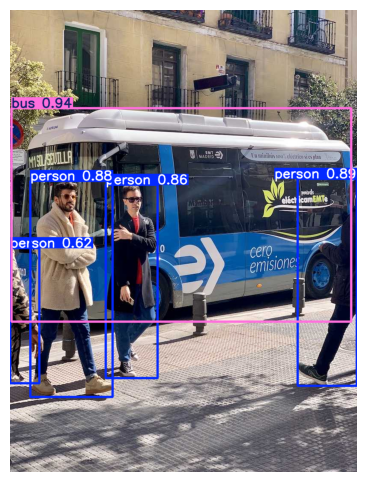

In [40]:
annotated = result.plot()[:, :, ::-1]

plt.figure(figsize=(8, 6))
plt.imshow(annotated)
plt.axis("off")
plt.show()

## 11. A grid

YOLO não desliza uma janela: redimensiona a imagem para `imgsz=640` e divide em células.
YOLO11 tem **3 grids** (heads P3/P4/P5), strides 8, 16 e 32.

Cada célula propõe boxes. Em laranja, a célula do **centro** de cada detecção.

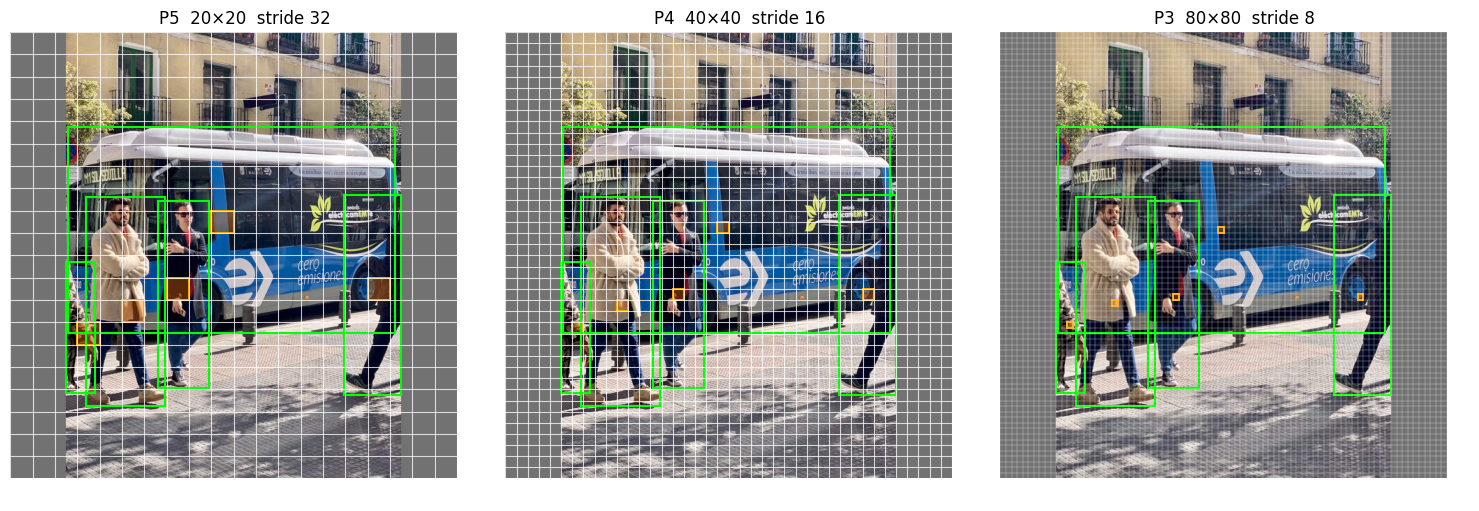

input 640×640: 8400 células no total (80² + 40² + 20²)


In [41]:
imgsz = 640
im = Image.open(image_path).convert("RGB")
ow, oh = im.size
scale = imgsz / max(ow, oh)
nw, nh = int(ow * scale), int(oh * scale)
pad_x = (imgsz - nw) // 2
pad_y = (imgsz - nh) // 2
canvas = Image.new("RGB", (imgsz, imgsz), (114, 114, 114))
canvas.paste(im.resize((nw, nh)), (pad_x, pad_y))

xyxy = result.boxes.xyxy.cpu()
centers = []
for x1, y1, x2, y2 in xyxy.tolist():
    cx = (x1 + x2) / 2 * scale + pad_x
    cy = (y1 + y2) / 2 * scale + pad_y
    centers.append((cx, cy))

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, stride, title in zip(
    axes,
    (32, 16, 8),
    ("P5  20×20  stride 32", "P4  40×40  stride 16", "P3  80×80  stride 8"),
):
    ax.imshow(canvas)
    lw = 0.8 if stride >= 16 else 0.25
    ax.vlines(range(0, imgsz + 1, stride), 0, imgsz, colors="white", linewidth=lw, alpha=0.75)
    ax.hlines(range(0, imgsz + 1, stride), 0, imgsz, colors="white", linewidth=lw, alpha=0.75)
    for cx, cy in centers:
        col, row = int(cx // stride), int(cy // stride)
        ax.add_patch(Rectangle(
            (col * stride, row * stride), stride, stride,
            fill=True, facecolor=(1.0, 0.45, 0.0, 0.35),
            edgecolor="orange", linewidth=1.4,
        ))
    for x1, y1, x2, y2 in xyxy.tolist():
        bx1 = x1 * scale + pad_x
        by1 = y1 * scale + pad_y
        bx2 = x2 * scale + pad_x
        by2 = y2 * scale + pad_y
        ax.add_patch(Rectangle(
            (bx1, by1), bx2 - bx1, by2 - by1,
            fill=False, edgecolor="lime", linewidth=1.5,
        ))
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()

n_cells = sum((imgsz // s) ** 2 for s in (8, 16, 32))
print(f"input {imgsz}×{imgsz}: {n_cells} células no total (80² + 40² + 20²)")

## 12. NMS e confiança

Cada célula da grid pode gerar uma box. O NMS fica com a de maior confiança
quando o IoU entre elas passa do limiar.

- `iou=1.0` → quase não suprime (**antes**)
- `iou=0.7` → NMS padrão (**depois**)

`conf` é o outro parafuso: abaixo do limiar a box nem entra no NMS.

antes do NMS:  47 boxes
depois do NMS: 5 boxes


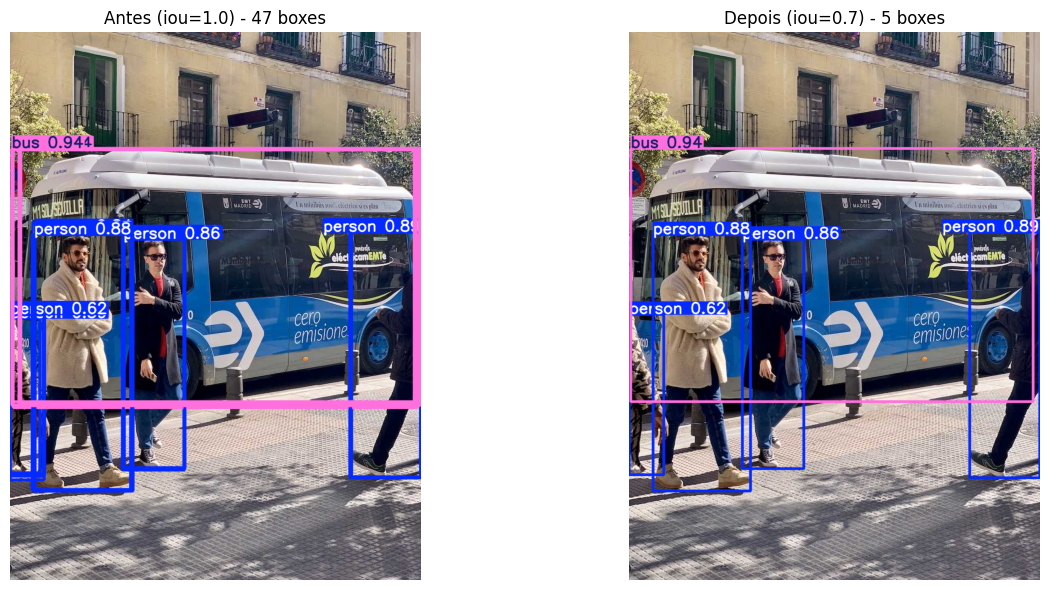

In [42]:
before = model.predict(source=str(image_path), conf=0.25, iou=1.0, verbose=False)[0]
after = model.predict(source=str(image_path), conf=0.25, iou=0.7, verbose=False)[0]
print(f"antes do NMS:  {len(before.boxes)} boxes")
print(f"depois do NMS: {len(after.boxes)} boxes")

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].imshow(before.plot()[:, :, ::-1])
axes[0].set_title(f"Antes (iou=1.0) - {len(before.boxes)} boxes")
axes[0].axis("off")
axes[1].imshow(after.plot()[:, :, ::-1])
axes[1].set_title(f"Depois (iou=0.7) - {len(after.boxes)} boxes")
axes[1].axis("off")
plt.tight_layout()
plt.show()

conf=0.1: 43 boxes
conf=0.5: 5 boxes


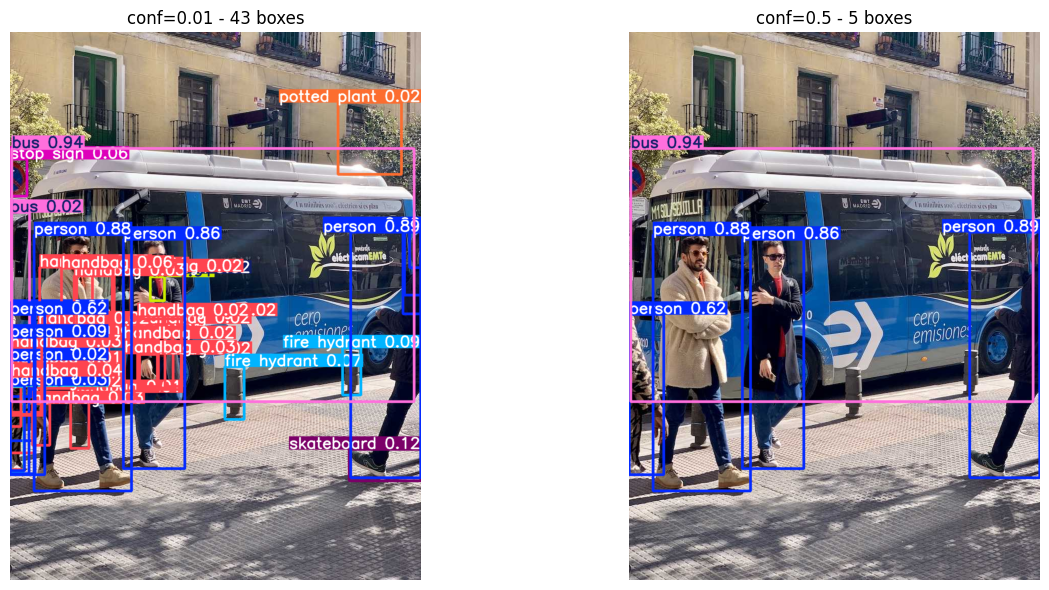

In [43]:
low = model.predict(source=str(image_path), conf=0.01, iou=0.7, verbose=False)[0]
high = model.predict(source=str(image_path), conf=0.5, iou=0.7, verbose=False)[0]
print(f"conf=0.1: {len(low.boxes)} boxes")
print(f"conf=0.5: {len(high.boxes)} boxes")

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].imshow(low.plot()[:, :, ::-1])
axes[0].set_title(f"conf=0.01 - {len(low.boxes)} boxes")
axes[0].axis("off")
axes[1].imshow(high.plot()[:, :, ::-1])
axes[1].set_title(f"conf=0.5 - {len(high.boxes)} boxes")
axes[1].axis("off")
plt.tight_layout()
plt.show()

## 13. Formato do dataset

YOLO não lê um CSV: ele espera **pastas espelhadas**.
Cada imagem tem um `.txt` com o **mesmo nome**.

```
coco8/
├── coco8.yaml
├── images/
│   ├── train/     000000000009.jpg
│   └── val/
└── labels/
    ├── train/     000000000009.txt
    └── val/
```

In [44]:
root = HERE / "coco8"
for split in ("train", "val"):
    print(f"{split}/")
    for img in sorted((root / "images" / split).glob("*.jpg")):
        label = root / "labels" / split / f"{img.stem}.txt"
        n_objs = len(label.read_text().splitlines()) if label.exists() else 0
        print(f"  {img.name}  <->  {label.name}  ({n_objs} objetos)")
    print()

train/
  000000000009.jpg  <->  000000000009.txt  (8 objetos)
  000000000025.jpg  <->  000000000025.txt  (2 objetos)
  000000000030.jpg  <->  000000000030.txt  (2 objetos)
  000000000034.jpg  <->  000000000034.txt  (1 objetos)

val/
  000000000036.jpg  <->  000000000036.txt  (2 objetos)
  000000000042.jpg  <->  000000000042.txt  (1 objetos)
  000000000049.jpg  <->  000000000049.txt  (9 objetos)
  000000000061.jpg  <->  000000000061.txt  (5 objetos)



## 14. O YAML

O arquivo `coco8/coco8.yaml` é o mapa do dataset:

- sem `path`: a raiz é a pasta do YAML (`coco8/`)
- `train` / `val`: pastas de imagens (relativas à raiz)
- `names`: id da classe → nome

In [45]:
yaml_text = DATA_YAML.read_text()
print(yaml_text.split("names:")[0])
print("names:  (algumas classes do COCO)")
for i in [0, 2, 5, 22, 23, 45, 49, 50, 58, 75]:
    print(f"  {i}: {model.names[i]}")

train: images/train
val: images/val


names:  (algumas classes do COCO)
  0: person
  2: car
  5: bus
  22: zebra
  23: giraffe
  45: bowl
  49: orange
  50: broccoli
  58: potted plant
  75: vase


## 15. Formato das labels

Um `.txt` por imagem. **Uma linha = um objeto:**

```
class_id  x_center  y_center  width  height
```

Valores **normalizados** (0 a 1):

- `x_center`, `y_center`: centro da box, em fração da largura/altura
- `width`, `height`: tamanho da box, também em fração

Origem `(0, 0)` no canto **superior esquerdo**.

In [46]:
label_path = HERE / "coco8" / "labels" / "train" / "000000000009.txt"
print(label_path.name)
print(label_path.read_text())

000000000009.txt
45 0.479492 0.688771 0.955609 0.5955
45 0.736516 0.247188 0.498875 0.476417
50 0.637063 0.732938 0.494125 0.510583
45 0.339438 0.418896 0.678875 0.7815
49 0.646836 0.132552 0.118047 0.0969375
49 0.773148 0.129802 0.0907344 0.0972292
49 0.668297 0.226906 0.131281 0.146896
49 0.642859 0.0792187 0.148063 0.148062



## 16. Ler uma linha

Exemplo: `45 0.479 0.689 0.956 0.596`

1. `45` → classe (`bowl`)
2. centro em ~48% da largura, ~69% da altura
3. box ocupa ~96% da largura e ~60% da altura

In [47]:
sample_path = HERE / "coco8" / "images" / "train" / "000000000009.jpg"
sample = Image.open(sample_path)
W, H = sample.size
print(f"Imagem: {W} x {H}")
print()

for line in label_path.read_text().splitlines():
    cls_id, xc, yc, bw, bh = map(float, line.split())
    cls_id = int(cls_id)
    x1 = (xc - bw / 2) * W
    y1 = (yc - bh / 2) * H
    x2 = (xc + bw / 2) * W
    y2 = (yc + bh / 2) * H
    print(
        f"{model.names[cls_id]:12s}  "
        f"norm=({xc:.3f}, {yc:.3f}, {bw:.3f}, {bh:.3f})  "
        f"px=({x1:.0f}, {y1:.0f}, {x2:.0f}, {y2:.0f})"
    )

Imagem: 640 x 480

bowl          norm=(0.479, 0.689, 0.956, 0.596)  px=(1, 188, 613, 474)
bowl          norm=(0.737, 0.247, 0.499, 0.476)  px=(312, 4, 631, 233)
broccoli      norm=(0.637, 0.733, 0.494, 0.511)  px=(250, 229, 566, 474)
bowl          norm=(0.339, 0.419, 0.679, 0.781)  px=(0, 14, 434, 389)
orange        norm=(0.647, 0.133, 0.118, 0.097)  px=(376, 40, 452, 87)
orange        norm=(0.773, 0.130, 0.091, 0.097)  px=(466, 39, 524, 86)
orange        norm=(0.668, 0.227, 0.131, 0.147)  px=(386, 74, 470, 144)
orange        norm=(0.643, 0.079, 0.148, 0.148)  px=(364, 2, 459, 74)


## 17. Desenhar as labels na imagem

A conversão inversa: normalizado → pixels, para conferir a anotação.

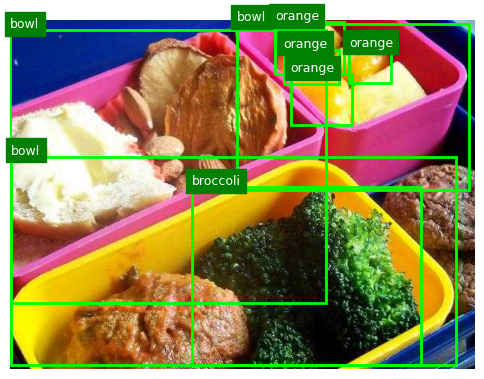

In [48]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(sample)

for line in label_path.read_text().splitlines():
    cls_id, xc, yc, bw, bh = map(float, line.split())
    cls_id = int(cls_id)
    x1 = (xc - bw / 2) * W
    y1 = (yc - bh / 2) * H
    ax.add_patch(
        Rectangle(
            (x1, y1),
            bw * W,
            bh * H,
            fill=False,
            edgecolor="lime",
            linewidth=2,
        )
    )
    ax.text(
        x1,
        y1,
        model.names[cls_id],
        color="white",
        fontsize=9,
        backgroundcolor="green",
        va="bottom",
    )

ax.axis("off")
plt.show()

## 18. Treino

Fine-tuning dos pesos COCO no coco8.

In [49]:
train_results = model.train(
    data=str(DATA_YAML),
    epochs=5,
    batch=8,
    imgsz=(640, 640),
    device=device,
    workers=8,
    pretrained=True,
    optimizer="auto",
    lr0=0.01,
    patience=100,
    project=str(HERE / "runs"),
    name="yolo_coco8",
    exist_ok=True,
)

New https://pypi.org/project/ultralytics/8.4.192 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.3.192 🚀 Python-3.13.5 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 4050 Laptop GPU, 5773MiB)
engine/trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/home/thyago/luxai/deep-learning-pratica/exemplos-aula-03/detection/coco8/coco8.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=5, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=(640, 640), int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/home/thyago/luxai/deep-learning-

## 19. Validação

mAP50 e mAP50-95 são as métricas padrão de detecção.

In [50]:
metrics = model.val()
print("mAP50:    ", float(metrics.box.map50))
print("mAP50-95: ", float(metrics.box.map))

Ultralytics 8.3.192 🚀 Python-3.13.5 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 4050 Laptop GPU, 5773MiB)
YOLO11n summary (fused): 100 layers, 2,616,248 parameters, 0 gradients, 6.5 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2370.5±1030.0 MB/s, size: 54.0 KB)
val: Scanning /home/thyago/luxai/deep-learning-pratica/exemplos-aula-03/detection/coco8/labels/val.cache... 4 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 4/4 17050.0it/s 0.0s0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 7.7it/s 0.1s
                   all          4         17   0.000457     0.0167      0.016    0.00962
                person          3         10    0.00274        0.1     0.0962     0.0577
                   dog          1          1          0          0          0          0
                 horse          1          2          0          0          0          0
              elephant          1          2          0   

## 20. Inferência com o modelo treinado

5 épocas em 4 imagens não bastam: o modelo esquece o COCO.
O ônibus deixa de ser detectado. Nas seções de save/export voltamos ao YOLO11n.

In [51]:
results_ft = model.predict(source=str(image_path), conf=0.25, verbose=False)
print("Detecções:", len(results_ft[0].boxes))

Detecções: 5


## 21. O treino já salvou pesos

O `train()` grava `runs/yolo_coco8/weights/best.pt` e `last.pt`.

In [52]:
weights_dir = HERE / "runs" / "yolo_coco8" / "weights"
for p in sorted(weights_dir.glob("*.pt")):
    print(p.name, f"{p.stat().st_size / 1e6:.1f} MB")

best.pt 5.5 MB
last.pt 5.5 MB


## 22. Salvar um `.pt` na mão

Voltamos ao YOLO11n pré-treinado e gravamos em `pesos/pt/`.

In [53]:
ckpt_path = PESOS_PT / "yolo11n.pt"
model = YOLO(str(ckpt_path) if ckpt_path.exists() else "yolo11n.pt")
model.save(str(ckpt_path))
print("salvo:", ckpt_path)
print(f"{ckpt_path.stat().st_size / 1e6:.1f} MB")

salvo: /home/thyago/luxai/deep-learning-pratica/exemplos-aula-03/detection/pesos/pt/yolo11n.pt
5.6 MB


## 23. Formatos de exportação

`export()` converte o modelo para outro runtime:

| formato | arquivo | uso |
|---|---|---|
| PyTorch | `.pt` | treino / fine-tuning |
| TorchScript | `.torchscript` | C++ / produção PyTorch |
| ONNX | `.onnx` | OpenCV, ONNX Runtime, muitos engines |
| OpenVINO | pasta | CPU Intel |
| TensorRT | `.engine` | GPU NVIDIA |
| CoreML | `.mlpackage` | iOS |
| TFLite | `.tflite` | mobile / edge |
| NCNN | pasta | mobile |

ONNX é o mais comum para deploy. Precisa de `onnx` e `onnxscript`.

In [54]:
exported = Path(model.export(format="onnx", imgsz=(640, 640), opset=18))
for f in exported.parent.glob(exported.name + "*"):
    dest = PESOS_ONNX / f.name
    if f.resolve() != dest.resolve():
        f.replace(dest)
onnx_path = PESOS_ONNX / exported.name
print("ONNX:", onnx_path)

Ultralytics 8.3.192 🚀 Python-3.13.5 torch-2.11.0+cu128 CPU (13th Gen Intel Core(TM) i7-13620H)
YOLO11n summary (fused): 100 layers, 2,616,248 parameters, 0 gradients, 6.5 GFLOPs

PyTorch: starting from '/home/thyago/luxai/deep-learning-pratica/exemplos-aula-03/detection/pesos/pt/yolo11n.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 84, 8400) (5.4 MB)

ONNX: starting export with onnx 1.19.0 opset 18...
ONNX: slimming with onnxslim 0.1.98...
ONNX: export success ✅ 2.1s, saved as '/home/thyago/luxai/deep-learning-pratica/exemplos-aula-03/detection/pesos/pt/yolo11n.onnx' (10.1 MB)

Export complete (2.3s)
Results saved to /home/thyago/luxai/deep-learning-pratica/exemplos-aula-03/detection/pesos/pt
Predict:         yolo predict task=detect model=/home/thyago/luxai/deep-learning-pratica/exemplos-aula-03/detection/pesos/pt/yolo11n.onnx imgsz=640  
Validate:        yolo val task=detect model=/home/thyago/luxai/deep-learning-pratica/exemplos-aula-03/detection/pesos/pt/yolo11

## 24. Carregar o `.pt`

detect 80 classes
Detecções: 5


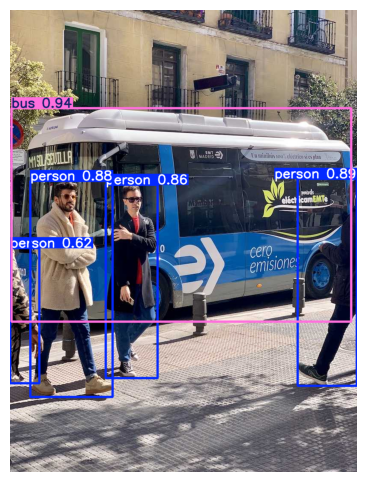

In [55]:
ckpt_path = PESOS_PT / "yolo11n.pt"
loaded_pt = YOLO(str(ckpt_path), task="detect")
print(loaded_pt.task, len(loaded_pt.names), "classes")

results_pt = loaded_pt.predict(source=str(image_path), conf=0.25, verbose=False)
print("Detecções:", len(results_pt[0].boxes))

plt.figure(figsize=(8, 6))
plt.imshow(results_pt[0].plot()[:, :, ::-1])
plt.axis("off")
plt.show()

## 25. Carregar o ONNX

`task="detect"` precisa ser explícito: o `.onnx` não traz essa metadata.
`device="cpu"` evita o warning do ONNX Runtime CUDA.

Loading /home/thyago/luxai/deep-learning-pratica/exemplos-aula-03/detection/pesos/onnx/yolo11n.onnx for ONNX Runtime inference...
Using ONNX Runtime CPUExecutionProvider
ONNX: /home/thyago/luxai/deep-learning-pratica/exemplos-aula-03/detection/pesos/onnx/yolo11n.onnx
Detecções: 5


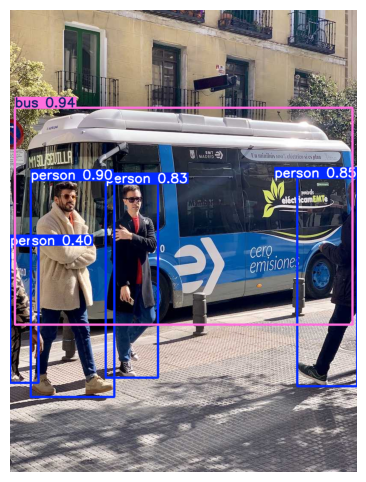

In [56]:
HERE = Path.cwd()
if not (HERE / "imagens" / "bus.jpg").exists():
    HERE = Path("exemplos-aula-03/detection")
image_path = HERE / "imagens" / "bus.jpg"
PESOS_PT = HERE / "pesos" / "pt"
PESOS_ONNX = HERE / "pesos" / "onnx"

onnx_path = PESOS_ONNX / "yolo11n.onnx"
if not onnx_path.exists():
    pt = PESOS_PT / "yolo11n.pt"
    exported = Path(YOLO(str(pt) if pt.exists() else "yolo11n.pt").export(format="onnx", imgsz=(640, 640), opset=18))
    PESOS_ONNX.mkdir(parents=True, exist_ok=True)
    for f in exported.parent.glob(exported.name + "*"):
        dest = PESOS_ONNX / f.name
        if f.resolve() != dest.resolve():
            f.replace(dest)
    onnx_path = PESOS_ONNX / exported.name

loaded_onnx = YOLO(str(onnx_path), task="detect")
results_onnx = loaded_onnx.predict(
    source=str(image_path),
    conf=0.25,
    imgsz=(640, 640),
    device="cpu",
    verbose=False,
)
print("ONNX:", onnx_path)
print("Detecções:", len(results_onnx[0].boxes))

plt.figure(figsize=(8, 6))
plt.imshow(results_onnx[0].plot()[:, :, ::-1])
plt.axis("off")
plt.show()